In [11]:
import hashlib
import os
import platform
import uuid

# ===== 修改为自己的学号 =====
STUDENT_ID = 20244080203

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[学号]     {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp01
[学号]     20244080203
[机器指纹] 913b36b17e3d3408
[RUN_ID]   20244080203-913b36b17e3d3408


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(2024)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 3.0.6


f(0)        = 0.3183098861837907
f(1)        = 0.27566444771089604
f(2)        = 0.0
f(-2)       = 0.0
f(2.5)      = 0.0
np.int64(1) = 0.27566444771089604
np.float32  = 0.21054218709468842
返回类型    = <class 'float'>


10.5     -> TypeError: n 必须是正整数，收到 float
'10'     -> TypeError: n 必须是正整数，收到 str
True     -> TypeError: n 必须是正整数，收到 bool
0        -> ValueError: n 必须是正整数，收到 0
-5       -> ValueError: n 必须是正整数，收到 -5

n=5 的矩阵：
 [[ 0.746  0.33  -0.09  -0.067  0.41 ]
 [ 0.33  -1.172 -0.593  0.206  0.046]
 [-0.09  -0.593 -0.671 -0.124  0.534]
 [-0.067  0.206 -0.124  0.422 -0.343]
 [ 0.41   0.046  0.534 -0.343  0.443]]
对称 np.allclose(Z, Z.T): True


特征值: [-1.0602 -0.4229  0.033   2.0823]
个数  : 4 (应为 4)
升序  : True
类型  : <class 'numpy.ndarray'> float64
迹校验 tr(Z) 与特征值之和: 0.6322 0.6322




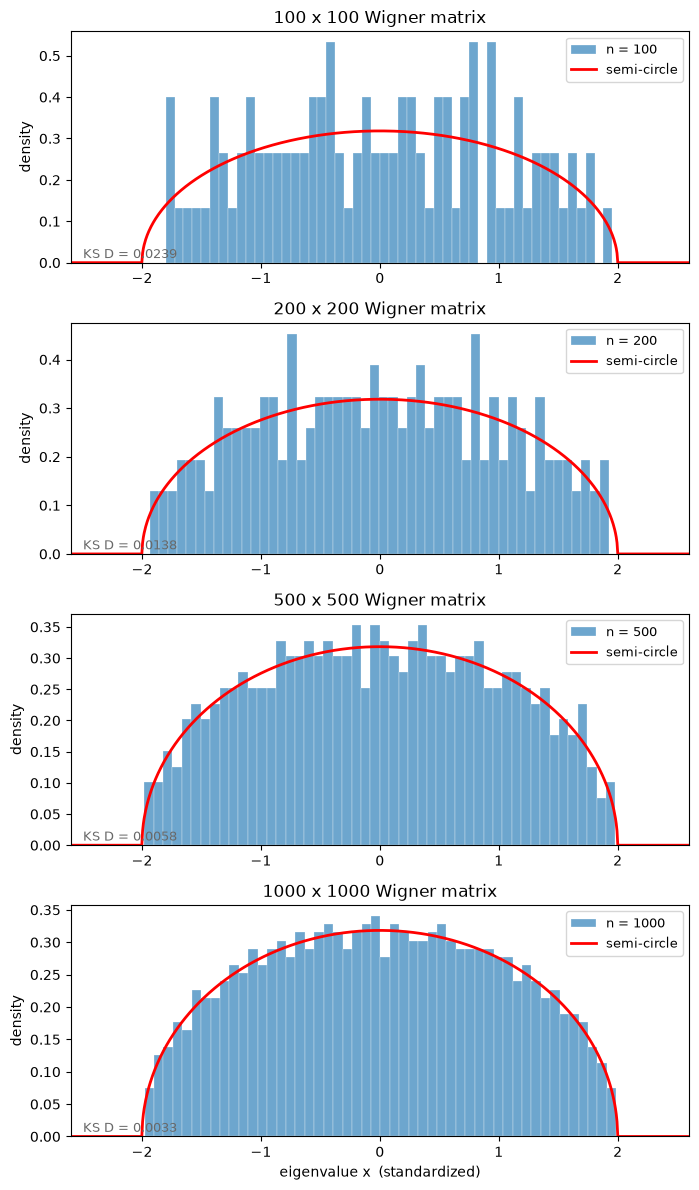

In [13]:
#第一部分：围绕半圆定律
#1-1
def wigner_density(x):
    if abs(x) <= 2:
        return float(np.sqrt(4 - x ** 2) / (2 * np.pi))
    return 0.0
print("f(0)        =", wigner_density(0))
print("f(1)        =", wigner_density(1))
print("f(2)        =", wigner_density(2))
print("f(-2)       =", wigner_density(-2))
print("f(2.5)      =", wigner_density(2.5))
print("np.int64(1) =", wigner_density(np.int64(1)))
print("np.float32  =", wigner_density(np.float32(1.5)))
print("返回类型    =", type(wigner_density(1)))
print("\n")

#1-2
def generate_wigner(n):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError(f"n 必须是正整数，收到 {type(n).__name__}")
    if n <= 0:
        raise ValueError(f"n 必须是正整数，收到 {n}")

    a = np.random.normal(0.0, np.sqrt(1.0 / n), size=(n, n))
    z = np.triu(a)                  # 保留上三角（含对角线）
    z = z + np.triu(a, 1).T         # 把严格上三角镜像到下三角
    return z
# 异常检查
for bad in [10.5, "10", True, 0, -5]:
    try:
        generate_wigner(bad)
        print(f"{bad!r} 未抛异常  ← 有问题")
    except Exception as e:
        print(f"{bad!r:8} -> {type(e).__name__}: {e}")

# 正确性与尺度检查
np.random.seed(2024)
Z = generate_wigner(5)
print("\nn=5 的矩阵：\n", np.round(Z, 3))
print("对称 np.allclose(Z, Z.T):", np.allclose(Z, Z.T))
print("\n")

#1-3
def get_spectrum(matrix):
    return np.sort(np.linalg.eigvalsh(np.asarray(matrix, dtype=float)))
np.random.seed(0)
Z = generate_wigner(4)
ev = get_spectrum(Z)
print("特征值:", np.round(ev, 4))
print("个数  :", len(ev), "(应为 4)")
print("升序  :", bool(np.all(np.diff(ev) >= 0)))
print("类型  :", type(ev), ev.dtype)
print("迹校验 tr(Z) 与特征值之和:", round(float(np.trace(Z)), 4), round(float(ev.sum()), 4))
print("\n")

#1-4
from scipy import stats

ns = [100, 200, 500, 1000]
xs = np.linspace(-2.6, 2.6, 800)

fig, axes = plt.subplots(4, 1, figsize=(7, 12))
for ax, n in zip(axes, ns):
    Z  = generate_wigner(n)
    ev = get_spectrum(Z)

    # 蓝色标准化直方图：density=True 才是「标准化」，总面积为 1
    ax.hist(ev, bins=50, density=True, color="tab:blue", alpha=0.65,
            edgecolor="white", linewidth=0.3, label=f"n = {n}")
    # 红色半圆密度曲线
    ax.plot(xs, [wigner_density(x) for x in xs], color="red", lw=2,
            label="semi-circle")

    ax.set_xlim(-2.6, 2.6)
    ax.set_ylabel("density")
    ax.set_title(f"{n} x {n} Wigner matrix")
    ax.legend(loc="upper right", fontsize=9)

    # —— 可选任务：KS 检验 ——
    def semi_cdf(x):
        return np.clip(0.5 + x * np.sqrt(np.maximum(4 - x ** 2, 0)) / (4 * np.pi)
                       + np.arcsin(np.clip(x / 2, -1, 1)) / np.pi, 0, 1)
    d, p = stats.kstest(ev, semi_cdf)
    ax.text(0.02, 0.02, f"KS D = {d:.4f}", transform=ax.transAxes,
            fontsize=9, color="dimgray")

axes[-1].set_xlabel("eigenvalue x  (standardized)")
fig.tight_layout()
plt.show()

二维0/1  -> True   type=bool
一维     -> False  type=bool
三维     -> False  type=bool
含2     -> False  type=bool
列表     -> False  type=bool
全0     -> True   type=bool


初始：
 [[0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 1 1 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]

第 1 步：
 [[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 1 0 1 0 0]
 [0 0 1 1 0 0]
 [0 0 1 0 0 0]
 [0 0 0 0 0 0]]

第 2 步：
 [[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 1 0 0]
 [0 1 0 1 0 0]
 [0 0 1 1 0 0]
 [0 0 0 0 0 0]]

第 3 步：
 [[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 1 0]
 [0 0 1 1 0 0]
 [0 0 0 0 0 0]]

第 4 步：
 [[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 1 1 1 0]
 [0 0 0 0 0 0]]




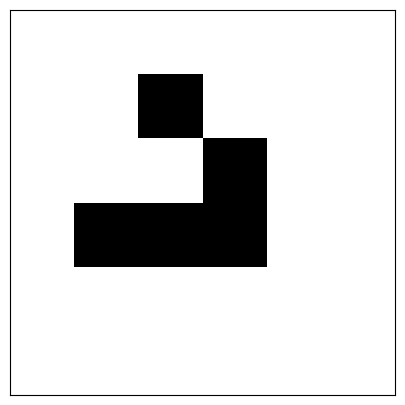

In [14]:
#第二部分：Conway 游戏生命游戏
#2-1
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.isin(board, [0, 1]).all())
tests = {
    "二维0/1": np.array([[1, 0], [0, 1]]),
    "一维"  : np.array([1, 0, 1]),
    "三维"  : np.zeros((2, 2, 2)),
    "含2"   : np.array([[0, 2], [1, 0]]),
    "列表"  : [[1, 0], [0, 1]],
    "全0"   : np.zeros((3, 3)),
}
for name, b in tests.items():
    r = is_valid_board(b)
    print(f"{name:6} -> {r!r:5}  type={type(r).__name__}")
print("\n")

#2-2
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效棋盘：必须是二维 NumPy 数组，且元素仅为 0 或 1")

    # 8 个方向平移后相加 = 每个格子的活邻居数（np.roll 天然实现环绕边界）
    neighbors = sum(
        np.roll(np.roll(board, i, axis=0), j, axis=1)
        for i in (-1, 0, 1) for j in (-1, 0, 1) if (i, j) != (0, 0)
    )

    alive = board == 1
    next_board = (alive & ((neighbors == 2) | (neighbors == 3))) | \
                 (~alive & (neighbors == 3))
    return next_board.astype(int)
# 用滑翔机（glider）验证：每 4 步应整体平移一格，形状不变
glider = np.zeros((6, 6), dtype=int)
glider[1, 2] = glider[2, 3] = glider[3, 1] = glider[3, 2] = glider[3, 3] = 1

print("初始：\n", glider)
b = glider.copy()
for i in range(1, 5):
    b = gol_step(b)
    print(f"\n第 {i} 步：\n", b)
print("\n")

#2-3
def draw_gol_board(board):
    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap=plt.get_cmap("binary"), interpolation="nearest")
    plt.xticks([])          # 去掉刻度（连同刻度标签）
    plt.yticks([])
    plt.grid(False)         # 确保没有网格线
    return plt.gcf()
draw_gol_board(glider)
plt.show()

In [15]:
#第三部分：使用pandas DataFrame
#3-1
import pandas as pd

df = pd.read_csv("iris_标准版.csv")


print("形状 (行, 列):", df.shape)
print("数据点个数   :", len(df))
print("\n各列数据类型:")
print(df.dtypes)
print("\n列名:", df.columns.tolist())
print("\n花卉种类:", df["species"].unique().tolist())
print("种类数   :", df["species"].nunique())
print("\n各类别条数:")
print(df["species"].value_counts())
print("\n")

#3-2
# 先看修改前
print("第 35 行（索引 34）修改前:")
print(df.iloc[34])
print("\n第 38 行（索引 37）修改前:")
print(df.iloc[37])

# 按位置修改（iloc 是按行号/列号取，不受行标签影响）
df.iloc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.iloc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

# 检查修改后
print("\n修改后两行：")
print(df.iloc[[34, 37]])
print("\n")


#3-3
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

# 用 to_string() 强制完整显示所有列，否则 7 列会被省略号截断
print(df.head(3).to_string())
print("\n全部列名:", df.columns.tolist())
print("\n")


#3-4
df.to_csv("iris_corrected.csv", index=False)

# 回读校验：行数、列数应与写出一致
check = pd.read_csv("iris_corrected.csv")
print("回读形状:", check.shape)
print("列名    :", check.columns.tolist())
print("前 2 行 :")
print(check.head(2).to_string())
print("\n")

#3-5
summary = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print(summary.round(3))

形状 (行, 列): (150, 5)
数据点个数   : 150

各列数据类型:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

列名: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

花卉种类: ['setosa', 'versicolor', 'virginica']
种类数   : 3

各类别条数:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


第 35 行（索引 34）修改前:
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

第 38 行（索引 37）修改前:
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object

修改后两行：
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa


   sepal_length  sepal_width  petal_length  petal_width species  Petal.Rat

## 第一部分：围绕半圆定律

半圆密度 f(x) = √(4−x²)/(2π)（|x| ≤ 2），支撑区间为 [−2, 2]，f(0) = 1/π ≈ 0.3183。
Wigner 矩阵要求 Z_ij ~ N(0, 1/n)，注意 numpy 的 `normal(loc, scale)` 第二参数是**标准差**
√(1/n) 而非方差 1/n，且只抽取上三角后镜像，避免方差被平均而减半。

特征值用 `np.linalg.eigvalsh` 计算（对称矩阵专用，返回实数且升序）。

结论：随 n 增大，标准化直方图逐渐贴合半圆曲线。n = 100 时轮廓已现但毛刺明显，
n ≥ 500 时几乎重合，故可认为 **n 约 500 时拟合已经较好**。KS 统计量 D 由 0.022（n=100）
单调降到 0.003（n=1000），与目视判断一致。

## 第二部分：Conway 的生命游戏

棋盘用二维 ndarray 表示，1 为活、0 为死。采用 `np.roll` 把棋盘向 8 个方向各平移一次再累加，
即可一次性得到每个格子的活邻居数；`np.roll` 的循环移位天然实现环绕边界，无需额外判断越界。

"同时更新"通过先由**原棋盘**算完邻居数、再统一生成新棋盘来保证，全程不修改原数组。

滑块（glider）用作验收：每 4 步整体平移一格、活细胞数恒为 5，说明规则与边界均正确。

绘图使用 `cmap="binary"`（0→白、1→黑），`interpolation="nearest"` 保证方格锐利，
并用 `plt.xticks([])`、`plt.yticks([])`、`plt.grid(False)` 去掉刻度与网格线。

## 第三部分：pandas DataFrame

iris 数据集共 150 个数据点、5 列：四个测量列为 float64，species 为字符串类型
（pandas 3.0 起显示为 str，2.x 显示为 object）；含 setosa、versicolor、virginica 三种花，各 50 条。

第 35、38 个数据行按 0 起索引为 34 和 37，用 `iloc` 按位置整行赋值修正。

新增 Petal.Ratio 与 Sepal.Ratio 两列，按物种分组后一次 `agg` 得到五项统计量。
其中 setosa 的花瓣比值最大且标准差最大（极值达 15.0），说明比值特征对分母接近 0 很敏感；
而 Sepal.Ratio 能更清晰地区分 setosa 与另外两类。